# SI: resonance in the calcium model

Supplementary to Figure 2. The calcium signalling model is, like the integral
feedback model of Figure 2, equivalent to a damped harmonic oscillator, so the
same adaptive switching strategy (panel E) drives it into resonance. Switching
$k_0$ or $k_3$ means watching the deviation $u = Ca - R_0$; switching $k_2$ means
watching the reservoir $D$, and watching $u$ instead damps it.

Figures (written to `plots/`, names kept from Figure 2):

* `figure2_panelH.pdf` (+ `_legend`) — resonance through $k_3$
* `figure2_panelH_{k0,k3,k2_naive,k2}.pdf` (+ one `_legend` per constant) — each rate constant in turn
* `figure2_growth_H.pdf` — the tolerance-band $g(Ca)$

In [1]:
"""SI calcium resonance — shared imports and plotting style."""
import sys
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle

sys.path.insert(0, '../src')
from rpa_control.style import set_style
from rpa_control.paths import save_fig

set_style()


In [2]:
# ======================================================================
# Plotting helpers (copied from figure2.ipynb)
# ======================================================================

SHADE_COLOR = '0.93'   # grey == soft spring, as in figure 2

def shade_spring(ax, t, ctrl, hard_val, soft_val):
    """Shade the time windows in which the soft spring is engaged.

    Grey means "soft spring" throughout figure 2: the post-switch span in
    panel B (beta1 halves, so k = alpha*beta1 drops) and the soft phases of
    the bang-bang schedule here.
    """
    is_soft = np.isclose(ctrl, soft_val)
    changes = np.where(np.diff(is_soft.astype(int)) != 0)[0]
    boundaries = np.concatenate([[0], changes + 1, [len(t) - 1]])
    for j in range(len(boundaries) - 1):
        i0, i1 = boundaries[j], boundaries[j + 1]
        if is_soft[i0]:
            ax.axvspan(t[i0], t[i1], color=SHADE_COLOR, lw=0)

def spring_legend(hard_label, soft_label, figsize=(1.0, 3.2), fontsize=11):
    """Tall, narrow key for the background shading: white = hard, grey = soft.

    Two large blocks stacked in a column, each labelled inside, so the swatches
    carry the same tone the panels use at a size that is actually readable. Its
    own figure, so it can sit beside a panel without eating axis space. The
    labels are arguments because the switched parameter differs by panel:
    beta1 in panel B, alpha in E/G/F/H.
    """
    gap = 0.05                       # sliver of page between the two blocks
    fig, ax = plt.subplots(figsize=figsize)
    for y0, face, label in [(1 + gap, 'white', hard_label),
                            (0.0, SHADE_COLOR, soft_label)]:
        ax.add_patch(Rectangle((0, y0), 1, 1 - gap, facecolor=face,
                               edgecolor='0.8', lw=0.8))
        ax.text(0.5, y0 + (1 - gap) / 2, label, ha='center', va='center',
                fontsize=fontsize, linespacing=1.5)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 2 + gap)
    ax.set_axis_off()
    fig.tight_layout(pad=0.05)
    return fig

KILL_COLOR = 'C3'   # trace colour while out of the tolerance band
FREE_COLOR = 'C0'

def plot_kill_colored(ax, t, B, mask, lw=1.5, color_on=KILL_COLOR, color_off=FREE_COLOR):
    """Plot a trace as a two-colour line: `color_on` over the stretches where
    `mask` is True, `color_off` elsewhere. In panels G and F the mask is "C is
    shrinking"; in the calcium panel it is simply "outside the tolerance band".
    Makes the band legible even when the trace dwarfs it."""
    pts = np.array([t, B]).T.reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    on = mask[:-1] | mask[1:]          # a boundary segment counts as active
    lc = LineCollection(segs, colors=[color_on if o else color_off for o in on],
                        linewidths=lw, capstyle='round')
    ax.add_collection(lc)
    ax.set_xlim(t.min(), t.max())
    ax.autoscale_view()
    return lc

# ======================================================================
# Dynamics (copied from figure2.ipynb)
# ======================================================================

def rk4_step(f, y, dt):
    k1 = f(y); k2 = f(y + 0.5*dt*k1)
    k3 = f(y + 0.5*dt*k2); k4 = f(y + dt*k3)
    return y + (dt/6.0) * (k1 + 2*k2 + 2*k3 + k4)

def adaptive_alpha(B, Bdot, alpha_hard, alpha_soft, eq):
    """Adaptive spring strategy:
    - Hard spring when moving toward equilibrium (accelerate return)
    - Soft spring when moving away from equilibrium (reduce overshoot)

    In general this is "hard while |B - eq| is falling", i.e. hard iff
    (B - eq) * Bdot < 0. Nothing here requires B to be the regulated variable:
    a caller that needs to watch some other state x passes (x, x_dot, hard,
    soft, 0.0). See run_adaptive_calcium_param.
    """
    if B > eq:
        return alpha_hard if Bdot < 0 else alpha_soft
    else:
        return alpha_hard if Bdot > 0 else alpha_soft

mu = 1.0       # unused by the calcium model; default eq of penalty_band
T = 10.0       # simulation horizon
dt = 0.005     # RK4 timestep for adaptive simulations

def penalty_band(B, radius=0.0, eq=mu):
    """Two-sided kill signal: active once B leaves the band eq +/- radius."""
    return np.maximum(np.abs(eq - B) - radius, 0.0)

# ======================================================================
# Calcium model
# ======================================================================

# --- Panel H (SI): calcium model ---
CALCIUM = dict(
    k0=1.0, k1=1.0, k2=20.0, R0=1.0, Vcl=0.0,
    k3=1.0,                       # base value; the runner overwrites whichever
    k3_hard=5.0, k3_soft=1.0,     # constant it is switching
    #  Tolerance band around R0, in panel F's two-sided sense: calcium is out
    #  of spec on BOTH sides of the setpoint (hypo- and hypercalcaemia alike),
    #  so the band, not the one-sided form of panel G, is what fits here.
    #  There is no tumour in this model -- the band is only a range, and 0.25
    #  puts the first crossing at t ~ 2.8, inside the window panel H shows.
    radius=0.25,
    x0=[1.01, 0.0],
)

def calcium_rhs(y, p):
    """Every rate constant is read from `p`, which the bang-bang controller
    may have just written to -- so this stays correct when k0, k2 or k3 is the
    one being switched."""
    Ca, D = y
    P = p['k0'] * (p['R0'] - Ca)
    return np.array([p['k1']*P + p['k2']*D - p['Vcl'], p['k3']*P])

def run_adaptive_calcium_param(param, hard, soft, cp=CALCIUM, watch='u'):
    """Bang-bang on ONE calcium rate constant, by the same rule as the spring:
    the hard value while the watched state is falling back toward zero, the soft
    value while it grows. `watch` names that state -- 'u' for the deviation
    Ca - R0, 'D' for the reservoir -- and which one is right depends on the
    parameter; see CALCIUM_SWEEP. The control trace comes back both as 'ctrl'
    and under the parameter's name."""
    p = dict(cp)
    n_steps = int(T / dt)
    t_arr = np.linspace(0, T, n_steps + 1)
    y = np.zeros((n_steps + 1, 2)); y[0] = cp['x0']
    ctrl = np.zeros(n_steps + 1)
    for i in range(n_steps):
        Ca, D = y[i]
        P = p['k0'] * (p['R0'] - Ca)
        u, u_dot = Ca - p['R0'], p['k1']*P + p['k2']*D - p['Vcl']
        D_dot = p['k3'] * P
        x, x_dot = (u, u_dot) if watch == 'u' else (D, D_dot)
        p[param] = adaptive_alpha(x, x_dot, hard, soft, 0.0)
        ctrl[i] = p[param]
        y[i+1] = rk4_step(lambda y_: calcium_rhs(y_, p), y[i], dt)
    ctrl[-1] = ctrl[-2]
    return dict(t=t_arr, y=y, ctrl=ctrl, **{param: ctrl})

def run_adaptive_calcium(cp=CALCIUM):
    return run_adaptive_calcium_param('k3', cp['k3_hard'], cp['k3_soft'], cp)

# --- SI: the same strategy driven through each rate constant in turn.
#     Pumping a swing means standing up at the bottom of the arc: what matters
#     is the timing, not the effort, and a quarter cycle off drags the swing to
#     a stop instead. Each knob here pumps a different swing. Undamped, the
#     model conserves
#         E = 1/2 * k0*k3 * u^2  +  1/2 * k2 * D^2,      u = Ca - R0
#     and a bang-bang parameter gains energy when it is raised at the peak of
#     whichever state it multiplies in E. So k0 and k3 are conjugate to u --
#     raise them when Ca is furthest from the setpoint -- while k2 is conjugate
#     to D, whose peak falls exactly where u = 0. Watching the wrong state does
#     not merely under-pump: it is a quarter cycle off, so it damps. The two k2
#     rows below are the same run under both rules, which is the demonstration.
#     Every entry swings k0*k2*k3 over the same 20 <-> 100.
CALCIUM_SWEEP = [
    dict(tag='k0',       param='k0', hard=5.0,   soft=1.0,  watch='u',
         base=dict(CALCIUM, k2=20.0, k3=1.0)),
    dict(tag='k3',       param='k3', hard=5.0,   soft=1.0,  watch='u',
         base=dict(CALCIUM, k0=1.0,  k2=20.0)),
    dict(tag='k2_naive', param='k2', hard=100.0, soft=20.0, watch='u',
         base=dict(CALCIUM, k0=1.0,  k3=1.0)),
    dict(tag='k2',       param='k2', hard=100.0, soft=20.0, watch='D',
         base=dict(CALCIUM, k0=1.0,  k3=1.0)),
]

**Panel H** — The Calcium signaling model is also equivalent to a damped harmonic oscillator.

The 3-variable Calcium model:

$$P = k_0(R_0 - Ca), \qquad \frac{dCa}{dt} = k_1 P + k_2 D - V_{cl}, \qquad \frac{dD}{dt} = k_3 P$$

reduces to a single second-order ODE directly in $Ca$:

$$\frac{d^2Ca}{dt^2} + k_1 k_0 \frac{dCa}{dt} + k_2 k_3 k_0\, Ca = k_2 k_3 k_0\, R_0$$

with:

| Physical quantity | Parameter |
|---|---|
| Mass $m$ | $1$ |
| Damping $c$ | $k_1 k_0$ |
| **Spring constant $k$** | $k_2 k_3 k_0$ |
| Equilibrium $Ca_{\text{eq}}$ | $R_0$ |

See the full derivation in the SI.

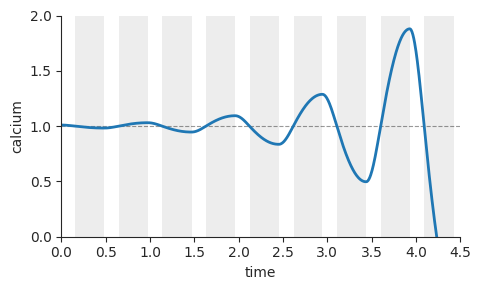

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_panelH.pdf


In [3]:
# SI: calcium model under the same adaptive strategy
data_H = run_adaptive_calcium()

fig, ax = plt.subplots(1, 1, figsize=(5, 3))

shade_spring(ax, data_H['t'], data_H['k3'], CALCIUM['k3_hard'], CALCIUM['k3_soft'])
ax.plot(data_H['t'], data_H['y'][:, 0], lw=2, color='C0')
ax.axhline(CALCIUM['R0'], color='black', ls='--', lw=0.8, alpha=0.4, zorder=1.5)

ax.set_ylabel('calcium')
ax.set_xlabel('time')
ax.set_xlim(0, 4.5)
ax.set_ylim(0, 2)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

save_fig(fig, 'figure2_panelH.pdf')

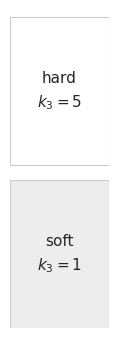

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_panelH_legend.pdf


In [4]:
# Key for the grey background in panel H: grey == soft spring.
# Panel H switches k3, so these are its two values; k = k0*k2*k3 with k0 and
# k2 fixed. Values come from CALCIUM, so the key cannot drift from the simulation.
fig = spring_legend(
    hard_label=f"hard\n$k_3 = {CALCIUM['k3_hard']:g}$",
    soft_label=f"soft\n$k_3 = {CALCIUM['k3_soft']:g}$")
plt.show()

save_fig(fig, 'figure2_panelH_legend.pdf')

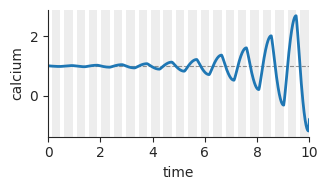

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_panelH_k0.pdf


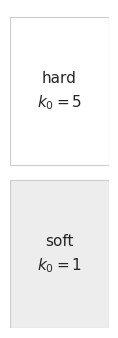

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_panelH_k0_legend.pdf


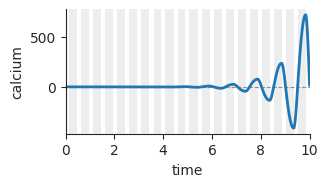

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_panelH_k3.pdf


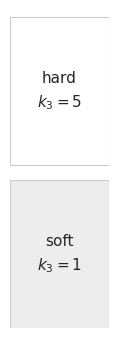

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_panelH_k3_legend.pdf


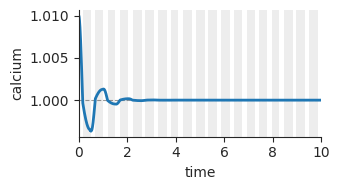

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_panelH_k2_naive.pdf


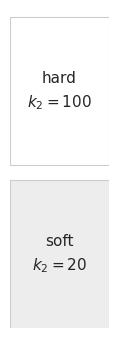

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_panelH_k2_legend.pdf


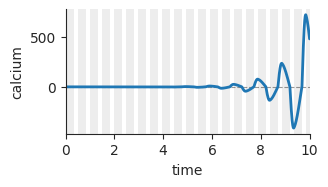

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_panelH_k2.pdf


In [5]:
# SI: resonance driven through k0, k2 and k3 in turn -- panel H's plot, once per
# run. Each swings the spring constant k0*k2*k3 over the same 20 <-> 100, so the
# panels differ only in which constant moves and which state the controller
# watches. The two k2 rows are the same run under both rules: watching u is a
# quarter cycle off for k2 and damps it, watching D resonates.
legends_done = set()
for cfg in CALCIUM_SWEEP:
    d = run_adaptive_calcium_param(cfg['param'], cfg['hard'], cfg['soft'],
                                   cfg['base'], watch=cfg['watch'])

    fig, ax = plt.subplots(1, 1, figsize=(3.5, 2))

    shade_spring(ax, d['t'], d['ctrl'], cfg['hard'], cfg['soft'])
    ax.plot(d['t'], d['y'][:, 0], lw=2, color='C0')
    ax.axhline(cfg['base']['R0'], color='black', ls='--', lw=0.8, alpha=0.4,
               zorder=1.5)

    name, watched = cfg['param'], cfg['watch']
    # ax.set_title(f'switching ${name[0]}_{name[1]}$ '
    #              f'({cfg["soft"]:g} $\\leftrightarrow$ {cfg["hard"]:g}), '
    #              f'watching ${watched}$', fontsize=8, loc='left')
    ax.set_ylabel('calcium')
    ax.set_xlabel('time')
    ax.set_xlim(0, T)                # shared: the time axis is the comparison
    # y is left to autoscale. The amplitudes differ by ~5 orders of magnitude,
    # so no one linear window holds them all -- the tick labels carry the size,
    # the shape carries whether it resonates at all.
    sns.despine(ax=ax)

    plt.tight_layout()
    plt.show()

    save_fig(fig, f'figure2_panelH_{cfg["tag"]}.pdf')

    # Key for the grey background: one per switched constant, since the two
    # k2 rows share the same hard/soft values. Values come from CALCIUM_SWEEP,
    # so the key cannot drift from the simulation.
    if name not in legends_done:
        legends_done.add(name)
        sym = f"{name[0]}_{name[1]}"
        fig = spring_legend(
            hard_label=f"hard\n${sym} = {cfg['hard']:g}$",
            soft_label=f"soft\n${sym} = {cfg['soft']:g}$")
        plt.show()

        save_fig(fig, f'figure2_panelH_{name}_legend.pdf')

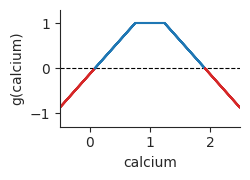

Figure saved to /home/amir/RL/autodiff-control/plots/figure2_growth_H.pdf


In [6]:
# g(Ca) for the calcium panel, plotted on its own -- the counterpart of the
# g(B) plots above. The calcium model has no tumour, so c1 and c2 here set the
# SHAPE of the curve only and never enter the ODE; what they cannot drift from
# is the band, since radius and the setpoint come straight from CALCIUM.
# Tolerance-band form, as in panel F: flat inside the band, falling on BOTH
# sides, because calcium is out of spec above and below the setpoint alike.
CAL_G = dict(c1=1.0, c2=1.5, radius=CALCIUM['radius'], eq=CALCIUM['R0'])

Ca_grid = CALCIUM['R0'] + np.linspace(-1.5, 1.5, 2001)   # centred on setpoint
g_Ca = CAL_G['c1'] - CAL_G['c2'] * penalty_band(Ca_grid, CAL_G['radius'],
                                                CAL_G['eq'])

fig, ax = plt.subplots(1, 1, figsize=(2.6, 1.9))

ax.axhline(0, color='black', lw=0.8, ls='--', zorder=1)
plot_kill_colored(ax, Ca_grid, g_Ca, g_Ca < 0)

# roots of g, i.e. where the curve leaves the in-spec half-plane
half = CAL_G['radius'] + CAL_G['c1'] / CAL_G['c2']
roots = [CAL_G['eq'] - half, CAL_G['eq'] + half]

ax.set_xlabel('calcium')
ax.set_ylabel('g(calcium)')
ax.set_xlim(Ca_grid.min(), Ca_grid.max())
ax.set_ylim(-1.3, 1.3)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

save_fig(fig, 'figure2_growth_H.pdf')

### SI: Derivation — Calcium Model as a Damped Mass-Spring System

**Given System:**

$$P = k_0(R_0 - Ca) \tag{1}$$

$$\frac{dCa}{dt} = k_1 P + k_2 D - V_{cl} \tag{2}$$

$$\frac{dD}{dt} = k_3 P \tag{3}$$

**Step 1:** Substitute $P$ from Eq. 1 into Eqs. 2 and 3:

$$\frac{dCa}{dt} = k_1 k_0(R_0 - Ca) + k_2 D - V_{cl}$$

$$\frac{dD}{dt} = k_3 k_0(R_0 - Ca)$$

**Step 2:** Differentiate the $\frac{dCa}{dt}$ equation with respect to $t$ (all $k$'s, $R_0$, $V_{cl}$ constant):

$$\frac{d^2Ca}{dt^2} = -k_1 k_0 \frac{dCa}{dt} + k_2 \frac{dD}{dt}$$

**Step 3:** Substitute $\frac{dD}{dt}$ from Step 1:

$$\frac{d^2Ca}{dt^2} = -k_1 k_0 \frac{dCa}{dt} + k_2 k_3 k_0(R_0 - Ca)$$

**Step 4:** Rearrange into standard second-order form:

$$\frac{d^2Ca}{dt^2} + k_1 k_0 \frac{dCa}{dt} + k_2 k_3 k_0\, Ca = k_2 k_3 k_0\, R_0$$

**Step 5:** Map to the damped mass-spring equation $m\ddot{x} + c\dot{x} + kx = F_{\text{ext}}$:

| Physical quantity | Our system |
|---|---|
| Mass ($m$) | $1$ |
| Damping coefficient ($c$) | $k_1 k_0$ |
| Spring constant ($k$) | $k_2 k_3 k_0$ |
| External force ($F_{\text{ext}}$) | $k_2 k_3 k_0\, R_0$ |

**Step 6:** At steady state, $\frac{dD}{dt} = 0$ requires $Ca = R_0$. Define $x(t) = Ca(t) - R_0$:

$$\ddot{x} + k_1 k_0\,\dot{x} + k_2 k_3 k_0(x + R_0) = k_2 k_3 k_0\, R_0$$

$$\boxed{\ddot{x} + k_1 k_0\,\dot{x} + k_2 k_3 k_0\,x = 0}$$

This confirms the Calcium dynamics behave as a damped spring with spring constant $k = k_2 k_3 k_0$, oscillating around $Ca_{\text{eq}} = R_0$.